# Numerical Instability of Golden Mean Recurrence

Tái tạo thí nghiệm trong *Numerical Recipes: The Art of Scientific Computing*,
ấn bản 3, §1.1.4 **Stability**, tr. 11–12.

Với $\phi=(\sqrt{5}-1)/2\approx0.618034$, tính $y_n=\phi^n$ cho
$n=0,\ldots,100$ bằng hai cách:

- **Direct:** tính độc lập từng lũy thừa $\widehat\phi^{\,n}$.
- **Recurrence:** $y_{n+1}=y_{n-1}-y_n$, khởi tạo $y_0=1$, $y_1=\widehat\phi$.

Thử nghiệm dùng cả `np.float32` và `np.float64`; $\widehat\phi$ được tính hoàn toàn
trong kiểu tương ứng. Giá trị tham chiếu là $\phi^n$ tính bằng `mpmath` với
**100 chữ số thập phân**, nên “nghiệm chính xác” trên hình được hiểu là tham chiếu
độ chính xác cao. Hai phương pháp dùng chung $\widehat\phi$ trong mỗi kiểu.

**Chạy:** chọn Python kernel có `numpy`, `matplotlib`, `mpmath` và `ipykernel`,
rồi **Run All**. Bảng và hình hiển thị inline; không có lệnh ghi ảnh hay dữ liệu ra file.

In [1]:
%matplotlib inline
import sys
from html import escape

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import mpmath as mp
from IPython.display import HTML, Markdown, display

mp.mp.dps = 100
N = 100
n_values = np.arange(N + 1)
plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'axes.grid': True,
    'grid.alpha': 0.25,
})
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | '
      f'Matplotlib {matplotlib.__version__} | mpmath {mp.__version__}')
print(f'n = 0, ..., {N}; mpmath precision = {mp.mp.dps} decimal digits')

Python 3.14.4 | NumPy 2.5.4 | Matplotlib 3.11.2 | mpmath 1.4.1
n = 0, ..., 100; mpmath precision = 100 decimal digits


## 1. Tham chiếu và kiểm soát kiểu dữ liệu

Các hằng `1`, `2`, `5`, phép căn, trừ, chia và phép lũy thừa đều được thực hiện
với kiểu đã chọn. Số mũ $0,\ldots,100$ biểu diễn chính xác trong cả hai kiểu;
`np.power(..., dtype=dtype)` buộc phép tính Direct giữ đúng độ chính xác.

Trong vòng truy hồi, `np.subtract(..., dtype=dtype)` và các kiểm tra `assert`
kiểm soát **kiểu của toán hạng lẫn kết quả trung gian**, thay vì chỉ ép kiểu khi
lưu vào mảng. Tham chiếu `mpmath` không tham gia vòng lặp này.

In [2]:
phi_mp = (mp.sqrt(5) - mp.mpf(1)) / mp.mpf(2)
reference_mp = [phi_mp ** int(n) for n in n_values]
# Chỉ làm tròn tham chiếu sang float64 để vẽ, không dùng mảng này tính sai số.
reference_plot = np.array([float(v) for v in reference_mp], dtype=np.float64)


def compute_sequences(dtype):
    """Tính Direct và Recurrence hoàn toàn bằng dtype được yêu cầu."""
    phi = np.divide(
        np.subtract(np.sqrt(dtype(5), dtype=dtype), dtype(1), dtype=dtype),
        dtype(2), dtype=dtype,
    )
    assert type(phi) is dtype
    exponents = n_values.astype(dtype)
    direct = np.power(phi, exponents, dtype=dtype)

    recurrence = np.empty(N + 1, dtype=dtype)
    recurrence[0], recurrence[1] = dtype(1), phi
    for n in range(1, N):
        previous, current = recurrence[n - 1], recurrence[n]
        assert type(previous) is dtype and type(current) is dtype
        next_value = np.subtract(previous, current, dtype=dtype)
        assert type(next_value) is dtype  # Kiểm tra trước khi ghi vào mảng.
        recurrence[n + 1] = next_value

    assert direct.dtype == recurrence.dtype == np.dtype(dtype)
    assert np.all(np.isfinite(direct)) and np.all(np.isfinite(recurrence))
    assert direct[0] == recurrence[0] == dtype(1)
    assert direct[1] == recurrence[1] == phi
    return {'dtype': dtype, 'phi': phi, 'direct': direct, 'recurrence': recurrence}


results = {dtype.__name__: compute_sequences(dtype)
           for dtype in (np.float32, np.float64)}
for name, result in results.items():
    print(f"{name}: phi = {result['phi']!r}; "
          f"Direct dtype = {result['direct'].dtype}; "
          f"Recurrence dtype = {result['recurrence'].dtype}")

float32: phi = np.float32(0.618034); Direct dtype = float32; Recurrence dtype = float32
float64: phi = np.float64(0.6180339887498949); Direct dtype = float64; Recurrence dtype = float64


## 2. Sai số so với tham chiếu độ chính xác cao

$$E_{\mathrm{abs}}(n)=|\widehat y_n-y_n^{\mathrm{ref}}|,\qquad
E_{\mathrm{rel}}(n)=\frac{E_{\mathrm{abs}}(n)}{|y_n^{\mathrm{ref}}|}.$$

Mỗi số máy được chuyển **chính xác** sang phân số nhị phân rồi sang `mpmath`;
phép trừ và phép chia để tính sai số đều dùng 100 chữ số. Việc chuyển
`float32` sang Python `float` trong hàm dưới chỉ dùng để phân tích kết quả
**sau khi** hoàn tất thí nghiệm và bảo toàn chính xác giá trị `float32`.
Tránh trừ hai mảng `float64` làm mất các sai số rất nhỏ của Direct `float64`.

In [3]:
def machine_to_mp(value):
    """Khôi phục đúng giá trị nhị phân của số float32/float64 hữu hạn."""
    numerator, denominator = float(value).as_integer_ratio()
    return mp.mpf(numerator) / mp.mpf(denominator)


for result in results.values():
    result['errors'] = {}
    for method in ('direct', 'recurrence'):
        abs_mp = [abs(machine_to_mp(value) - ref)
                  for value, ref in zip(result[method], reference_mp)]
        rel_mp = [err / abs(ref) for err, ref in zip(abs_mp, reference_mp)]
        result['errors'][method] = {
            'abs_mp': abs_mp,
            'rel_mp': rel_mp,
            # Các mảng float64 này chỉ phục vụ đồ thị.
            'absolute': np.array([float(v) for v in abs_mp], dtype=np.float64),
            'relative': np.array([float(v) for v in rel_mp], dtype=np.float64),
        }
        assert abs_mp[0] == rel_mp[0] == 0


def first_crossing(relative_errors, threshold):
    """Trả về n đầu tiên có sai số tương đối >= threshold; None nếu chưa có."""
    return next((n for n, err in enumerate(relative_errors)
                 if err >= threshold), None)


def show_table(headers, rows):
    """Bảng HTML inline; không cần pandas hoặc file trung gian."""
    head = ''.join(f'<th>{escape(str(h))}</th>' for h in headers)
    body = ''.join('<tr>' + ''.join(
        f'<td style="text-align:right;padding:5px 9px">{escape(str(v))}</td>'
        for v in row) + '</tr>' for row in rows)
    display(HTML(f'<div style="overflow-x:auto"><table>'
                 f'<thead><tr>{head}</tr></thead><tbody>{body}</tbody>'
                 f'</table></div>'))


def sci(value):
    return f'{float(value):.6e}'


summary_rows = []
for name, result in results.items():
    rec_errors = result['errors']['recurrence']['rel_mp']
    result['n_1pct'] = first_crossing(rec_errors, mp.mpf('0.01'))
    result['n_100pct'] = first_crossing(rec_errors, mp.mpf(1))
    summary_rows.append([
        name, sci(np.finfo(result['dtype']).eps),
        result['n_1pct'], result['n_100pct'],
        sci(rec_errors[-1]), sci(result['errors']['direct']['rel_mp'][-1]),
    ])

show_table(
    ['Kiểu', 'Machine epsilon', 'n đầu: Rec ≥ 1%', 'n đầu: Rec ≥ 100%',
     'Rel. Rec (n=100)', 'Rel. Direct (n=100)'], summary_rows,
)

Kiểu,Machine epsilon,n đầu: Rec ≥ 1%,n đầu: Rec ≥ 100%,Rel. Rec (n=100),Rel. Direct (n=100)
float32,1.192093e-07,15,20,4.605634e+33,2.680041e-06
float64,2.220446e-16,35,40,1.524095e+25,8.852010e-15


### Bảng giá trị tại một số chỉ số

Bảng hiển thị sáu chữ số sau dấu thập phân ở dạng khoa học; phép tính sai số
vẫn dùng toàn bộ độ chính xác nêu trên. Các mốc 1% và 100% là tiêu chí quan sát,
không phải định nghĩa duy nhất của mất ổn định.

In [4]:
selected_n = [0, 1, 10, 16, 20, 30, 38, 40, 60, 80, 100]
rows = []
for n in selected_n:
    for name, result in results.items():
        direct_err = result['errors']['direct']
        rec_err = result['errors']['recurrence']
        rows.append([
            name, n, sci(reference_mp[n]),
            sci(result['direct'][n]), sci(result['recurrence'][n]),
            sci(direct_err['abs_mp'][n]), sci(rec_err['abs_mp'][n]),
            sci(direct_err['rel_mp'][n]), sci(rec_err['rel_mp'][n]),
        ])
show_table(
    ['Kiểu', 'n', 'Tham chiếu', 'Direct', 'Recurrence',
     'Abs. Direct', 'Abs. Rec', 'Rel. Direct', 'Rel. Rec'], rows,
)

Kiểu,n,Tham chiếu,Direct,Recurrence,Abs. Direct,Abs. Rec,Rel. Direct,Rel. Rec
float32,0,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
float64,0,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
float32,1,6.180340e-01,6.180340e-01,6.180340e-01,1.641521e-08,1.641521e-08,2.656036e-08,2.656036e-08
float64,1,6.180340e-01,6.180340e-01,6.180340e-01,5.432115e-17,5.432115e-17,8.789347e-17,8.789347e-17
float32,10,8.130619e-03,8.130621e-03,8.129716e-03,2.409254e-09,9.028363e-07,2.963186e-07,1.110415e-04
float64,10,8.130619e-03,8.130619e-03,8.130619e-03,6.469358e-18,2.987663e-15,7.956784e-16,3.674583e-13
float32,16,4.531039e-04,4.531040e-04,4.369020e-04,1.784187e-10,1.620181e-05,3.937701e-07,3.575738e-02
float64,16,4.531039e-04,4.531039e-04,4.531039e-04,6.635128e-19,5.361498e-14,1.464372e-15,1.183282e-10
float32,20,6.610696e-05,6.610699e-05,-4.494190e-05,3.212031e-11,1.110489e-04,4.858839e-07,1.679836e+00
float64,20,6.610696e-05,6.610696e-05,6.610696e-05,1.163146e-19,3.674826e-13,1.759491e-15,5.558909e-09


## 3. Nghiệm tham chiếu và nghiệm tính được

Trục tung dùng **symlog** (log có dấu, tuyến tính rất gần 0) để thấy được cả
sự suy giảm của $\phi^n$ và sự đổi dấu, tăng biên độ của truy hồi. Log thông
thường sẽ che mất các giá trị âm. Direct gần trùng với tham chiếu trên hình.
Nhãn đồ thị dùng tiếng Anh để thuận tiện hiển thị trên các kernel khác nhau.

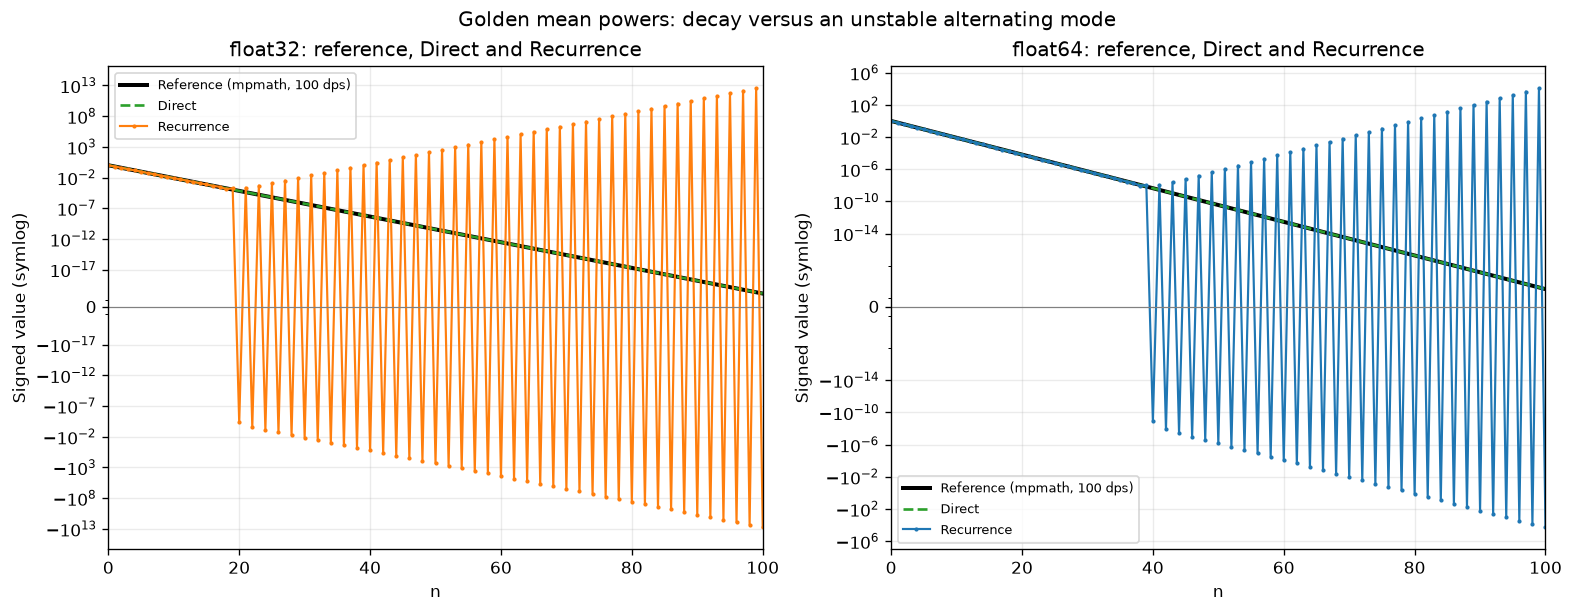

In [5]:
colors = {'float32': 'tab:orange', 'float64': 'tab:blue'}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for ax, (name, result) in zip(axes, results.items()):
    ax.plot(n_values, reference_plot, color='black', linewidth=2.4,
            label='Reference (mpmath, 100 dps)')
    ax.plot(n_values, result['direct'], color='tab:green', linestyle='--',
            linewidth=1.6, label='Direct')
    ax.plot(n_values, result['recurrence'], color=colors[name],
            linewidth=1.3, marker='.', markersize=3, label='Recurrence')
    ax.set_yscale('symlog', linthresh=1e-22)
    ax.set(xlabel='n', ylabel='Signed value (symlog)',
           title=f'{name}: reference, Direct and Recurrence', xlim=(0, N))
    # Bỏ nhãn log quá gần 0 để tránh chồng chữ trên trục symlog.
    ticks = [t for t in ax.get_yticks() if t == 0 or abs(t) >= 1e-17]
    ax.yaxis.set_major_locator(matplotlib.ticker.FixedLocator(ticks))
    ax.axhline(0, color='gray', linewidth=0.7)
    ax.legend(fontsize=8, loc='best')
fig.suptitle('Golden mean powers: decay versus an unstable alternating mode')
plt.show()
plt.close(fig)

## 4. Absolute error, relative error và so sánh hai kiểu

Hai đồ thị dưới có trục tung **logarithmic**. Sai số đúng bằng 0 (đặc biệt
$n=0$) được bỏ khỏi đường vẽ bằng `NaN`, không thay bằng một sai số giả.
Màu phân biệt kiểu dữ liệu, nét liền/nét đứt phân biệt phương pháp.
Đường ngang $E_{\mathrm{rel}}=1$ đánh dấu sai số tương đối 100%; dấu tròn
đánh dấu chỉ số đầu tiên chạm hoặc vượt ngưỡng này của truy hồi.

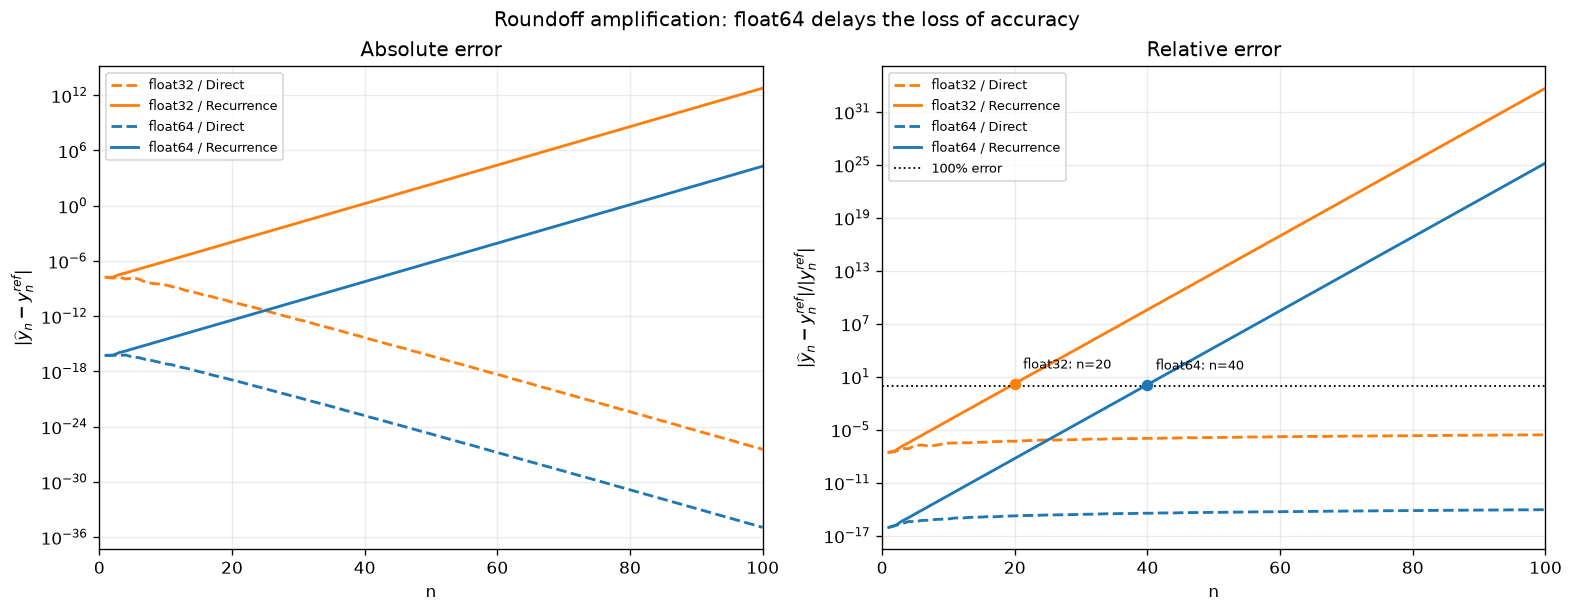

In [6]:
def positive_for_log(values):
    return np.where(values > 0, values, np.nan)


fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for name, result in results.items():
    for method, style in (('direct', '--'), ('recurrence', '-')):
        for ax, error_kind in zip(axes, ('absolute', 'relative')):
            ax.semilogy(
                n_values,
                positive_for_log(result['errors'][method][error_kind]),
                color=colors[name], linestyle=style, linewidth=1.7,
                label=f'{name} / {method.capitalize()}',
            )
    crossing = result['n_100pct']
    if crossing is not None:
        value = result['errors']['recurrence']['relative'][crossing]
        axes[1].scatter([crossing], [value], color=colors[name], s=35, zorder=5)
        axes[1].annotate(f'{name}: n={crossing}', (crossing, value),
                         xytext=(5, 9), textcoords='offset points', fontsize=8)

axes[0].set(title='Absolute error', ylabel=r'$|\widehat{y}_n-y_n^{ref}|$')
axes[1].set(title='Relative error',
            ylabel=r'$|\widehat{y}_n-y_n^{ref}|/|y_n^{ref}|$')
axes[1].axhline(1, color='black', linestyle=':', linewidth=1.1, label='100% error')
for ax in axes:
    ax.set(xlabel='n', xlim=(0, N))
    ax.legend(fontsize=8)
fig.suptitle('Roundoff amplification: float64 delays the loss of accuracy')
plt.show()
plt.close(fig)

## 5. Vì sao truy hồi mất ổn định?

Thay $y_n=r^n$ vào truy hồi cho phương trình đặc trưng

$$r^2+r-1=0,\qquad
r_1=\phi\approx0.618034,\qquad
r_2=-\frac{\sqrt5+1}{2}\approx-1.618034,\quad |r_2|>1.$$

Nghiệm tổng quát là $y_n=A\phi^n+B r_2^n$. Trong số học chính xác,
điều kiện đầu cho $A=1$, $B=0$. Làm tròn $y_1$ và sai số phát sinh trong
phép trừ có thể đưa vào một thành phần $B\ne0$. Thành phần này đổi dấu
và tăng theo $|r_2|^n$, trong khi nghiệm cần tìm giảm theo $\phi^n$.

Nếu chỉ xét nhiễu ban đầu $\delta=\widehat y_1-\phi$, với $e_0=0$,
$e_1=\delta$ và các bước sau chính xác, thì

$$e_n=\frac{\delta}{\phi-r_2}\left(\phi^n-r_2^n\right).$$

Vì vậy, khi thành phần không mong muốn chiếm ưu thế, sai số tuyệt đối tăng
xấp xỉ theo $|r_2|^n$, còn sai số tương đối tăng theo

$$\left(\frac{|r_2|}{\phi}\right)^n=\phi^{-2n}\approx2.618034^n.$$

Đây là **sự khuếch đại sai số làm tròn của thuật toán truy hồi tiến**.
Độ chính xác cao hơn làm giảm nhiễu ban đầu và trì hoãn thời điểm mất
độ chính xác, nhưng không loại bỏ nghiệm phụ tăng. Mốc quan sát có thể khác
đôi chút giữa cách khởi tạo, nền tảng và cách định nghĩa ngưỡng; sách mô tả
sự hỏng kết quả của `float32` vào khoảng $n=16$.

Direct cũng chịu làm tròn của $\widehat\phi$ và phép lũy thừa. Trong miền
$n\le100$ này, sai số do nhiễu ở $\phi$ chỉ tăng tương đối khoảng
$n|\delta|/\phi$ ở bậc nhất, nên nhỏ hơn nhiều so với truy hồi. Các giá trị
tham chiếu vẫn nằm trong miền số chuẩn của cả hai kiểu; hiện tượng quan sát
không phải do underflow hay overflow.

In [7]:
# Kiểm tra ý nghĩa số học của kết quả, ngoài các kiểm tra dtype trong vòng lặp.
assert min(reference_mp) > machine_to_mp(np.finfo(np.float32).tiny)
for result in results.values():
    assert len(result['recurrence']) == len(result['direct']) == N + 1
    assert result['n_100pct'] is not None
    assert max(result['errors']['direct']['rel_mp']) < mp.mpf('0.001')
    assert result['errors']['recurrence']['rel_mp'][-1] > 1
assert results['float32']['n_100pct'] < results['float64']['n_100pct']

r32, r64 = results['float32'], results['float64']
display(Markdown(
    f"**Kết luận từ lần chạy này.** Truy hồi đạt sai số tương đối ≥ 1% tại "
    f"$n={r32['n_1pct']}$ (`float32`) và $n={r64['n_1pct']}$ (`float64`); "
    f"đạt ≥ 100% tại $n={r32['n_100pct']}$ và $n={r64['n_100pct']}$. "
    f"Tại $n=100$, sai số tương đối của Direct lần lượt là "
    f"`{sci(r32['errors']['direct']['rel_mp'][-1])}` và "
    f"`{sci(r64['errors']['direct']['rel_mp'][-1])}`. "
    "Direct giữ độ chính xác tốt trên miền khảo sát, còn truy hồi tiến mất ổn định "
    "do khuếch đại nghiệm phụ. Dùng `float64` chỉ trì hoãn sự mất ổn định; "
    "để tính dãy này nên dùng Direct hoặc thuật toán khác có tính ổn định phù hợp."
))
print('Tất cả kiểm tra dtype, giá trị hữu hạn và hành vi sai số đã đạt.')

**Kết luận từ lần chạy này.** Truy hồi đạt sai số tương đối ≥ 1% tại $n=15$ (`float32`) và $n=35$ (`float64`); đạt ≥ 100% tại $n=20$ và $n=40$. Tại $n=100$, sai số tương đối của Direct lần lượt là `2.680041e-06` và `8.852010e-15`. Direct giữ độ chính xác tốt trên miền khảo sát, còn truy hồi tiến mất ổn định do khuếch đại nghiệm phụ. Dùng `float64` chỉ trì hoãn sự mất ổn định; để tính dãy này nên dùng Direct hoặc thuật toán khác có tính ổn định phù hợp.

Tất cả kiểm tra dtype, giá trị hữu hạn và hành vi sai số đã đạt.


**Nguồn:** W. H. Press, S. A. Teukolsky, W. T. Vetterling, B. P. Flannery,
*Numerical Recipes: The Art of Scientific Computing*, 3rd ed. (2007),
§1.1.4, tr. 11–12, phương trình (1.1.4)–(1.1.5).
Đối chiếu bản PDF có sẵn trong workspace:
[Chapter 1 — Preliminaries](<../../docs/Numerical Analysis/Numerical Recipes - The Art of Scientific Computing - 3rd Edition-25-60.pdf>).